# S6E11 Advanced Modeling: members, gates, per-fold scores and correlations

This notebook reads the saved out-of-fold library (`oof/full/*.npz`), `experiments/library.txt` and the run log in `experiments.md`. It retrains nothing: every number here was produced by the scripts in `experiments/` (one per idea) and the queue runner `experiments/run_queue.py`. It runs top to bottom in seconds.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Paths and names shared by every cell. The notebook runs from the competition folder, like the other notebooks.

In [2]:
OOF_DIR = Path("oof") / "full"
LIBRARY_FILE = Path("experiments") / "library.txt"
LOG_FILE = Path("experiments.md")
DATA_DIR = Path("data")
SUBMISSION_DIR = Path("submissions")
TARGET = "is_fraud"
REFIT_SUFFIX = "_refit"

## 1. Members

`load_member` decodes one member file; `run_log` turns the run-log table of `experiments.md` into a DataFrame so the gates and queue decisions can be filtered.

In [3]:
def load_member(name: str) -> dict:
    """Read one full-mode member `.npz` into a dict with its JSON config decoded."""
    with np.load(OOF_DIR / f"{name}.npz") as data:
        member = {key: data[key] for key in data.files}
    member["config"] = json.loads(str(member["config"]))
    return member


def run_log() -> pd.DataFrame:
    """Parse the auto-appended run log table at the end of `experiments.md` into a DataFrame."""
    text = LOG_FILE.read_text().split("## Run log", 1)[1]
    rows = [[part.strip() for part in line.strip().strip("|").split("|")] for line in text.splitlines() if re.match(r"\| \d\d-\d\d ", line)]
    return pd.DataFrame([row[:7] + [""] * (7 - len(row[:7])) for row in rows], columns=["time", "entry", "mode", "result", "detail", "extra", "verdict"])

### 1.1 Member table

Every full-mode member with its **single-model CV** (mean of the 5 fold AUCs on `folds.npy`), fold spread, runtime, refit tree count and whether it is in the accepted library. Refit files (test side only) are excluded.

In [4]:
library = LIBRARY_FILE.read_text().split()
names = sorted(path.stem for path in OOF_DIR.glob("*.npz") if not path.stem.endswith(REFIT_SUFFIX))
members = {name: load_member(name) for name in names}
member_table = pd.DataFrame([{"member": name, "model": m["config"].get("model"), "features": m["config"].get("features"), "cv": m["fold_auc"].mean(), "fold_std": m["fold_auc"].std(), "runtime_min": m["config"].get("runtime_s", np.nan) / 60, "refit_trees": m["config"].get("refit_trees"), "in_library": name in library} for name, m in members.items()]).sort_values("cv", ascending=False).reset_index(drop=True)
member_table.style.format({"cv": "{:.5f}", "fold_std": "{:.5f}", "runtime_min": "{:.1f}"})

,member,model,features,cv,fold_std,runtime_min,refit_trees,in_library
0,glm_boost_lgbm4,lgbm + GLM init_score,raw + TE,0.95029,0.00295,8.8,816.000000,False
1,glm_boost,xgb + GLM base_margin,raw + TE,0.95026,0.00295,7.6,741.000000,True
2,xgb_d2_te_gp,xgb,raw + TE + group-mean deviations,0.95023,0.00298,3.6,2092.000000,False
3,xgb_d2_te,xgb,raw + TE,0.95021,0.00302,4.0,2067.000000,True
4,lgbm4_te,lgbm,raw + TE,0.95012,0.00303,10.8,1981.000000,False
5,realmlp,realmlp,raw + TE + int categories,0.94993,0.00297,9.0,nan,False
6,te_xgb,xgb,"raw + TE(values, digit keys)",0.94940,0.00292,6.1,1909.000000,False
7,tabm,tabm,raw + TE + int categories,0.94932,0.00313,33.0,nan,False
8,glm,logistic,"log numerics, splines, flags, one-hot cats/low-card ints, one-hot values+keys (>=5), TE logits",0.94928,0.00293,3.2,nan,False
9,baseline,xgb,raw,0.94666,0.00310,2.2,1937.000000,True


### 1.2 Per-fold AUC

The gate needs ≥ 4/5 folds up, so per-fold numbers matter more than the mean. Folds 2 and 4 are consistently the hardest and easiest for every member, which is why gates compare members fold by fold rather than by their means.

In [5]:
per_fold = pd.DataFrame({name: m["fold_auc"] for name, m in members.items()}, index=[f"fold {k}" for k in range(5)]).T.loc[member_table["member"]]
per_fold.style.format("{:.5f}").background_gradient(axis=0, cmap="Greens")

,fold 0,fold 1,fold 2,fold 3,fold 4
glm_boost_lgbm4,0.94825,0.95042,0.94691,0.95031,0.95558
glm_boost,0.94823,0.95038,0.94689,0.95025,0.95555
xgb_d2_te_gp,0.94838,0.95046,0.94657,0.95025,0.95549
xgb_d2_te,0.94850,0.95063,0.94634,0.95014,0.95544
lgbm4_te,0.94841,0.95045,0.94625,0.95006,0.95541
realmlp,0.94801,0.95069,0.94595,0.95017,0.95481
te_xgb,0.94786,0.94985,0.94557,0.94929,0.95444
tabm,0.94712,0.95008,0.94564,0.94896,0.95478
glm,0.94722,0.94976,0.94590,0.94904,0.95447
baseline,0.94463,0.94751,0.94256,0.94681,0.95180


## 2. Gates and queue decisions

Every gate, kill check, prune round and stack fit appended to the run log. **Single** gates compare a variant with the model it replaces; **blend** gates compare the nested hill climb of the library with and without the candidate. Both need ≥ +5e-5 and ≥ 4/5 folds up.

In [6]:
log = run_log()
decisions = log[log["entry"].str.contains("GATE|QUEUE kill|PRUNE|STACK")].reset_index(drop=True)
decisions

,time,entry,mode,result,detail,extra,verdict
0,11-27 10:17,GATE single te_xgb vs baseline,full,Δ +0.00274,Δ per fold +0.00323 +0.00235 +0.00301 +0.00248...,5/5 up,PASS
1,11-27 10:21,GATE blend glm vs [te_xgb],full,"0.94940 → 0.95014, Δ +0.00074",Δ per fold +0.00047 +0.00076 +0.00096 +0.00068...,"5/5 up, weight 0.474, max ρ 0.97560",PASS
2,11-27 10:22,GATE blend xgb_d2_te vs [te_xgb glm],full,"0.95014 → 0.95042, Δ +0.00028",Δ per fold +0.00028 +0.00025 +0.00015 +0.00032...,"5/5 up, weight 0.590, max ρ 0.99192",PASS
3,11-27 10:30,GATE blend lgbm4_te vs [te_xgb glm xgb_d2_te],full,"0.95042 → 0.95044, Δ +0.00002",Δ per fold +0.00003 -0.00001 +0.00001 +0.00004...,"4/5 up, weight 0.277, max ρ 0.99672",FAIL
4,11-27 10:32,GATE blend glm_boost vs [te_xgb glm xgb_d2_te],full,"0.95042 → 0.95056, Δ +0.00014",Δ per fold +0.00009 -0.00005 +0.00025 +0.00023...,"4/5 up, weight 0.500, max ρ 0.99576",PASS
5,11-27 10:41,GATE blend baseline vs [te_xgb glm xgb_d2_te g...,full,"0.95056 → 0.95064, Δ +0.00009",Δ per fold -0.00000 +0.00014 +0.00009 +0.00015...,"4/5 up, weight 0.136, max ρ 0.96301",PASS
6,11-27 10:44,STACK hill_climb [4 members],full,0.95056,0.94870 0.95082 0.94694 0.95052 0.95580,vs best single +0.00030,te_xgb=0.130 glm=0.019 xgb_d2_te=0.352 glm_boo...
7,11-27 10:44,STACK logistic_stack [4 members],full,0.95058,0.94871 0.95083 0.94698 0.95052 0.95584,vs best single +0.00032,te_xgb=0.140 glm=0.084 xgb_d2_te=0.491 glm_boo...
8,11-27 10:48,STACK hill_climb [5 members],full,0.95064,0.94870 0.95096 0.94703 0.95066 0.95588,vs best single +0.00039,te_xgb=0.045 glm=0.000 xgb_d2_te=0.318 glm_boo...
9,11-27 10:48,STACK logistic_stack [5 members],full,0.95066,0.94874 0.95096 0.94705 0.95065 0.95589,vs best single +0.00040,te_xgb=0.042 glm=0.034 xgb_d2_te=0.452 glm_boo...


## 3. Correlations

Spearman rank correlation of the OOF predictions. AUC only sees ranks, so rank correlation is what limits how much a member can add to a blend: Phase 2's LGBM-4 failed its gate at ρ 0.9967 with XGB depth 2.

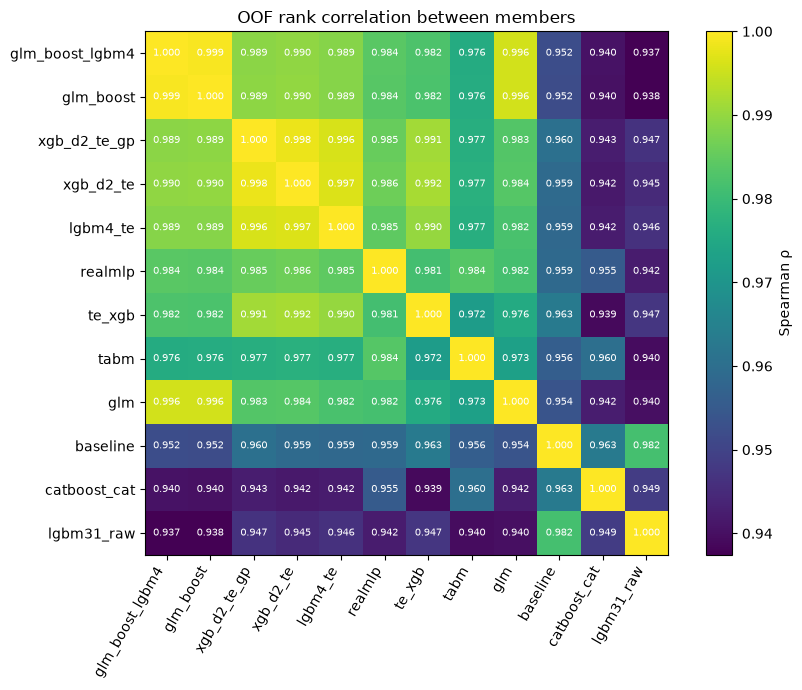

In [7]:
oof = pd.DataFrame({name: members[name]["oof"] for name in member_table["member"]})
correlation = oof.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation, cmap="viridis", vmin=correlation.min().min(), vmax=1)
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=60, ha="right")
ax.set_yticks(range(len(correlation)), correlation.index)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(j, i, f"{correlation.iat[i, j]:.3f}", ha="center", va="center", fontsize=7, color="white")
fig.colorbar(image, ax=ax, label="Spearman ρ")
ax.set_title("OOF rank correlation between members")
fig.tight_layout()
plt.show()

### 3.1 Most distinct members

For each library member, its highest correlation with any other library member. Lower means a more distinct view, which is what the blend gate rewards.

In [8]:
library_corr = correlation.loc[library, library].mask(np.eye(len(library), dtype=bool))
library_corr.max().sort_values().rename("max ρ with another library member").to_frame().style.format("{:.5f}")

,max ρ with another library member
baseline,0.95907
xgb_d2_te,0.98979
glm_boost,0.98979
